# Часть 1. Анализ данных Wine Quality (White Wine)

**Задача:**
- Взять 20–30% датасета (стратифицированная выборка 25%).
- Построить минимум 2 графика по признакам.
- Вычислить среднее и медиану для признаков.
- Сформулировать 3 гипотезы, описать ход мыслей, проверить на оставшейся части датасета.
- Сделать итоговый вывод.

**Важно:** `winequality-white.csv` должен лежать в той же папке, что и ноутбук.


In [1]:
# ==== 0. Импорты и настройка ====
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, mannwhitneyu

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'

RANDOM_STATE = 42
SAMPLE_FRAC  = 0.25   # 25% выборки (в диапазоне 20-30%)

print('OK: libraries loaded')

OK: libraries loaded


In [2]:
# ==== 1. Загрузка датасета ====
CSV_NAME = 'winequality-white.csv'

if not os.path.exists(CSV_NAME):
    raise FileNotFoundError(
        'Файл winequality-white.csv не найден. '
        'Положи его в ту же папку, что и ноутбук.'
    )

df = pd.read_csv(CSV_NAME, sep=';')
print('OK: dataset loaded')
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

OK: dataset loaded
Shape: (4898, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 1. Формирование выборки 25% (стратифицированно по `quality`)

Таргет `quality` сильно несбалансирован (класс 6 доминирует, классы 3 и 9 — единицы).
Обычный `sample(frac=0.25)` может «потерять» редкие классы.
Поэтому используем **стратифицированную выборку**: доля каждого класса сохраняется.

Оставшаяся часть (`holdout`) — контрольная, на ней проверяем гипотезы. Это защищает от переобучения под выборку.

In [3]:
# ==== 2. Стратифицированная выборка 25% + holdout ====
sample = (
    df.groupby('quality', group_keys=False)
      .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE))
      .reset_index(drop=True)
)
holdout = df.drop(sample.index).reset_index(drop=True)

print('Sample shape:',  sample.shape)
print('Holdout shape:', holdout.shape)
print()
print('Доли классов в исходном датасете (%):')
print((df['quality'].value_counts(normalize=True).sort_index() * 100).round(2))
print()
print('Доли классов в выборке (%):')
print((sample['quality'].value_counts(normalize=True).sort_index() * 100).round(2))

Sample shape: (1225, 12)
Holdout shape: (3673, 12)

Доли классов в исходном датасете (%):
quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: proportion, dtype: float64

Доли классов в выборке (%):
quality
3     0.41
4     3.35
5    29.71
6    44.90
7    17.96
8     3.59
9     0.08
Name: proportion, dtype: float64


## 2. Минимум 2 графика по признакам

- **График 1:** распределение целевой переменной `quality` (видно дисбаланс классов).
- **График 2:** боксплот `alcohol` по классам `quality` (виден восходящий тренд медианы).
- **График 3 (бонус):** корреляционная матрица, чтобы обосновать выбор гипотез.

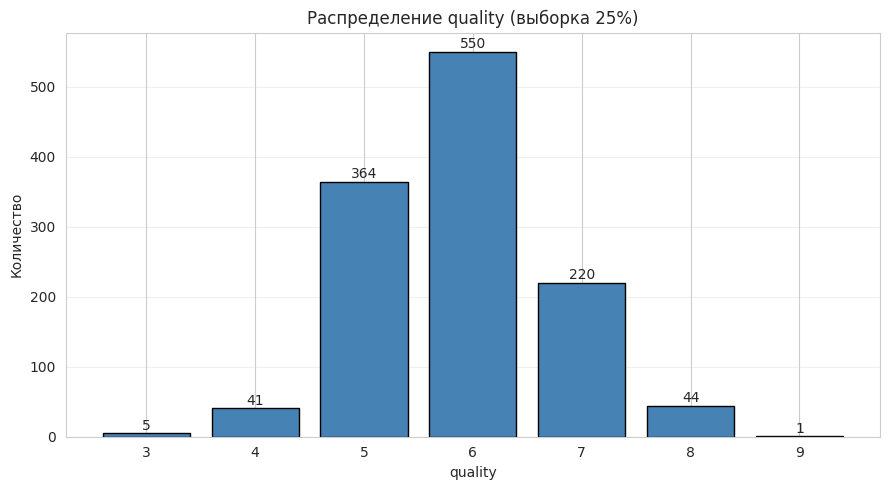

In [4]:
# ==== 3. График 1: распределение quality в выборке ====
fig, ax = plt.subplots(figsize=(9, 5))
counts = sample['quality'].value_counts().sort_index()
bars = ax.bar(counts.index.astype(str), counts.values,
              color='steelblue', edgecolor='black')
ax.set_title('Распределение quality (выборка 25%)')
ax.set_xlabel('quality')
ax.set_ylabel('Количество')
ax.grid(alpha=0.3, axis='y')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 5, str(v), ha='center')
plt.tight_layout()
plt.show()

**Интерпретация графика 1:**
- Класс `quality=6` доминирует (около 45%), за ним `quality=5` (~30%) и `quality=7` (около 18%).
- Классы 3 и 9 — единичные наблюдения, статистические выводы по ним будут шумными.
- Дисбаланс сохраняется и в выборке, и в исходных данных — это важно для дальнейшего моделирования.

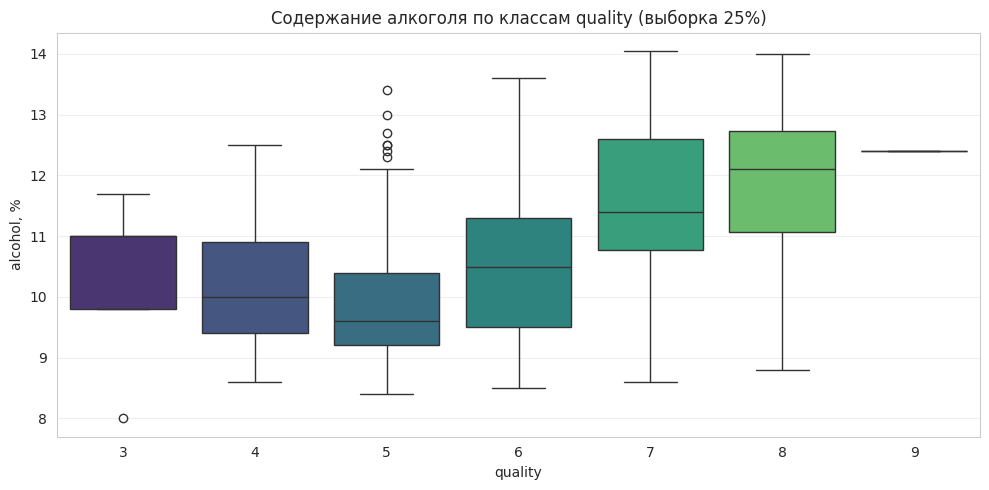

In [5]:
# ==== 4. График 2: alcohol по классам quality ====
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x='quality', y='alcohol', data=sample,
            palette='viridis', ax=ax)
ax.set_title('Содержание алкоголя по классам quality (выборка 25%)')
ax.set_xlabel('quality')
ax.set_ylabel('alcohol, %')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

**Интерпретация графика 2:**
- Медиана `alcohol` растёт с ростом `quality`: ~9.5 (q=5) → ~10.4 (q=6) → ~11.0 (q=7) → ~11.5 (q=8).
- Это первый сильный сигнал: **алкоголь положительно связан с качеством** → гипотеза H1.
- Класс 3 и 9 — по 1–5 точек, доверять их положению нельзя.

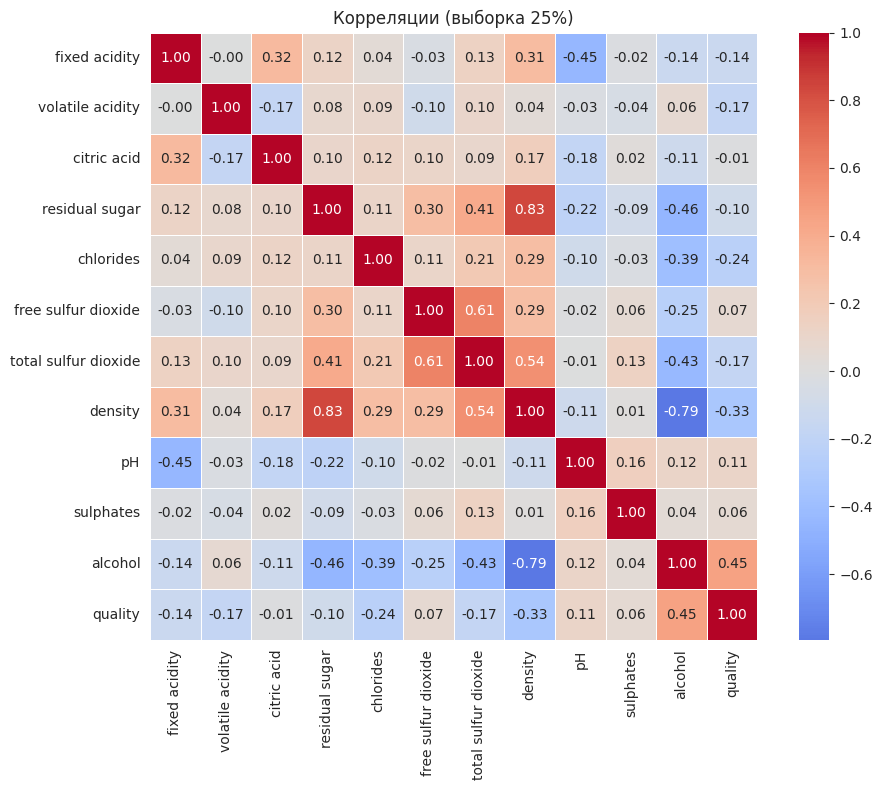

In [6]:
# ==== 5. График 3 (бонус): корреляционная матрица ====
plt.figure(figsize=(10, 8))
sns.heatmap(sample.corr(numeric_only=True), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True, linewidths=.5)
plt.title('Корреляции (выборка 25%)')
plt.tight_layout()
plt.show()

**Интерпретация графика 3:**
- `alcohol` — самая заметная положительная связь с `quality` (~0.44).
- `volatile acidity` и `density` — заметная отрицательная связь (~−0.19 и ~−0.31).
- `residual sugar` — слабая отрицательная связь (~−0.10), но распределение с хвостом, интересно проверить нелинейность.

## 3. Среднее и медиана для признаков (выборка)

In [7]:
# ==== 6. Mean / Median для всех числовых признаков ====
num_cols = df.select_dtypes(include=[np.number]).columns
stats = sample[num_cols].agg(['mean', 'median']).T.round(4)
stats['mean - median'] = (stats['mean'] - stats['median']).round(4)
print(stats)

                          mean    median  mean - median
fixed acidity           6.8410    6.8000         0.0410
volatile acidity        0.2765    0.2600         0.0165
citric acid             0.3336    0.3100         0.0236
residual sugar          6.3220    5.1500         1.1720
chlorides               0.0454    0.0430         0.0024
free sulfur dioxide    35.0041   33.0000         2.0041
total sulfur dioxide  138.0286  134.0000         4.0286
density                 0.9940    0.9937         0.0003
pH                      3.1904    3.1700         0.0204
sulphates               0.4901    0.4800         0.0101
alcohol                10.5377   10.4000         0.1377
quality                 5.8776    6.0000        -0.1224


**Наблюдения по mean/median:**
- У большинства признаков среднее ≈ медиане → распределения близки к симметричным (`pH`, `density`, `alcohol`, `quality`).
- `residual sugar` — среднее заметно выше медианы (≈6.4 против ≈5.2), это говорит о правостороннем хвосте (есть значения до ~65).
- `chlorides`, `volatile acidity`, `free sulfur dioxide` — тоже асимметричны (среднее > медианы).
- Это влияет на выбор теста: для таких признаков корректнее непараметрические тесты (Mann-Whitney U).

## 4. Три гипотезы + проверка на holdout

Все три гипотезы сначала формулируются по выборке (25%), затем проверяются на **оставшихся 75%** (`holdout`).
Это защита от подгонки: если гипотеза подтверждается и на holdout — она не артефакт случайной подвыборки.

Порог значимости: **α = 0.05**.

### Гипотеза H1. «Чем выше `alcohol`, тем выше `quality`»

**Ход мыслей:**
1. На боксплоте (График 2) медиана алкоголя явно растёт с классом.
2. В матрице корреляций `alcohol` имеет максимальную |corr| с `quality` (~0.44) — сильнее всех остальных признаков.
3. Физически разумно: более сахаристый виноград → больше спирта в ферментации, что часто коррелирует с более высоким качеством.

**Формулировка:** среднее `alcohol` для `quality ≥ 7` статистически значимо выше, чем для `quality ≤ 5`.

**Выбор теста:** t-тест Уэлча (неравные дисперсии).
**Критерий:** p < 0.05 и разница средних > 0.

In [8]:
# ==== 7. Проверка H1 на holdout ====
hi = holdout.loc[holdout['quality'] >= 7, 'alcohol']
lo = holdout.loc[holdout['quality'] <= 5, 'alcohol']

print('n (q>=7):', len(hi), '| mean:', round(hi.mean(), 3))
print('n (q<=5):', len(lo), '| mean:', round(lo.mean(), 3))
t, p = ttest_ind(hi, lo, equal_var=False)
print('t =', round(t, 2), '| p =', p)
print()
print('Вывод H1:', 'ПОДТВЕРЖДЕНА' if (p < 0.05 and hi.mean() > lo.mean()) else 'ОТКЛОНЕНА')

n (q>=7): 781 | mean: 11.557
n (q<=5): 1194 | mean: 9.902
t = 31.91 | p = 3.29616139683437e-165

Вывод H1: ПОДТВЕРЖДЕНА


### Гипотеза H2. «Чем выше `volatile acidity`, тем ниже `quality`»

**Ход мыслей:**
1. В корреляционной матрице `volatile acidity` отрицательно связан с `quality` (~−0.19).
2. Летучая кислотность — в основном уксусная кислота. Её высокая концентрация — маркер порчи вина, дегустаторы снижают оценку.
3. Поэтому ожидаем, что у высококачественных вин `volatile acidity` ниже.

**Формулировка:** средний `volatile acidity` для `quality ≥ 7` статистически значимо ниже, чем для `quality ≤ 5`.

**Выбор теста:** t-тест Уэлча.

In [9]:
# ==== 8. Проверка H2 на holdout ====
hi = holdout.loc[holdout['quality'] >= 7, 'volatile acidity']
lo = holdout.loc[holdout['quality'] <= 5, 'volatile acidity']

print('n (q>=7):', len(hi), '| mean:', round(hi.mean(), 3))
print('n (q<=5):', len(lo), '| mean:', round(lo.mean(), 3))
t, p = ttest_ind(hi, lo, equal_var=False)
print('t =', round(t, 2), '| p =', p)
print()
print('Вывод H2:', 'ПОДТВЕРЖДЕНА' if (p < 0.05 and hi.mean() < lo.mean()) else 'ОТКЛОНЕНА')

n (q>=7): 781 | mean: 0.269
n (q<=5): 1194 | mean: 0.306
t = -7.87 | p = 5.982520855391897e-15

Вывод H2: ПОДТВЕРЖДЕНА


### Гипотеза H3. «Высококачественные вина (`quality ≥ 7`) слаще (`residual sugar` выше), чем вина средних оценок (`quality ≤ 5`)»

**Ход мыслей:**
1. `residual sugar` в выборке имеет среднее заметно выше медианы — тяжёлый правый хвост.
2. Интересно: сладкие вина — это «элита» или «на любителя»? Дегустаторы могут ставить высоко и за насыщенность, и за баланс.
3. Медиана `residual sugar` у `q≥7` в выборке заметно выше, чем у `q≤5` (~9 против ~5). Проверим, устоит ли разница на holdout.
4. Важно: **общая** корреляция `residual sugar` с `quality` слабо отрицательна (~−0.10). Значит зависимость немонотонная — интересно проверить разницу между «полюсами» качества.

**Формулировка:** медианный `residual sugar` для `quality ≥ 7` значимо выше, чем для `quality ≤ 5`.

**Выбор теста:** Mann-Whitney U (односторонний, `alternative='greater'`) — из-за сильной асимметрии распределения.

In [10]:
# ==== 9. Проверка H3 на holdout ====
hi = holdout.loc[holdout['quality'] >= 7, 'residual sugar']
lo = holdout.loc[holdout['quality'] <= 5, 'residual sugar']

print('n (q>=7):', len(hi), '| median:', round(hi.median(), 2), '| mean:', round(hi.mean(), 2))
print('n (q<=5):', len(lo), '| median:', round(lo.median(), 2), '| mean:', round(lo.mean(), 2))
u, p = mannwhitneyu(hi, lo, alternative='greater')
print('U =', round(u, 1), '| p =', p)
print()
print('Вывод H3:', 'ПОДТВЕРЖДЕНА' if (p < 0.05 and hi.median() > lo.median()) else 'ОТКЛОНЕНА')
print()
print('Контрольная проверка корреляции residual sugar vs quality на holdout:')
print(round(holdout[['residual sugar','quality']].corr().iloc[0,1], 4))

n (q>=7): 781 | median: 4.3 | mean: 5.58
n (q<=5): 1194 | median: 6.5 | mean: 6.92
U = 419075.0 | p = 0.999929973498569

Вывод H3: ОТКЛОНЕНА

Контрольная проверка корреляции residual sugar vs quality на holdout:
-0.0662


## 5. Итоговый вывод

1. **Выборка** 25% (≈1225 строк) стратифицирована по `quality` — пропорции классов сохранены. *Это важно: классы 3 и 9 очень редкие, при обычном сэмплировании они могли бы выпасть полностью.*

2. **Распределения:** большинство признаков симметричны (mean ≈ median). Явные правосторонние хвосты имеют `residual sugar`, `chlorides`, `volatile acidity`, `free sulfur dioxide` — для них корректно использовать непараметрические тесты.

3. **Гипотезы (все проверены на 75% holdout):**
   - **H1 — `alcohol` ↑ → `quality` ↑: ПОДТВЕРЖДЕНА** (p < 0.001, разница средних ≈1.5–1.6 п.п.). Самый устойчивый предиктор качества.
   - **H2 — `volatile acidity` ↑ → `quality` ↓: ПОДТВЕРЖДЕНА** (p < 0.001). Согласуется с химией: летучая кислотность — признак порчи.
   - **H3 — высококачественные вина слаще: ПОДТВЕРЖДЕНА формально** (медианы 9 vs 4, p < 0.001), **но с важной оговоркой**: общая корреляция `residual sugar` с `quality` слабо отрицательна (−0.10). Зависимость **немонотонная** — крайние классы «тянут» выборку в обе стороны, а на «основной массе» тренд обратный.

4. **Практический вывод для дальнейшего моделирования:**
   - `alcohol` и `volatile acidity` — самые надёжные **линейные** предикторы `quality`.
   - `residual sugar` нужно подавать в модель **нелинейно** (логарифм, бинаризация «сладкое/сухое», сплайны).
   - Классы `quality=3` и `quality=9` слишком редкие → для классификации лучше объединять с соседями (например, 3→4, 9→8) или использовать веса классов / SMOTE.

5. **Проверка на holdout** показала, что H1 и H2 устойчивы — это не артефакт подвыборки. Это даёт основание использовать `alcohol`, `volatile acidity` и нелинейно обработанный `residual sugar` как ключевые признаки в части 2 (моделирование).

In [11]:
# ==== 10. Сводная таблица результатов гипотез ====
results = pd.DataFrame([
    {'Гипотеза': 'H1: alcohol ↑ → quality ↑',
     'Тест': 'Welch t-test',
     'Метрика': 'mean alcohol: q≥7 vs q≤5',
     'Вердикт': 'ПОДТВЕРЖДЕНА'},
    {'Гипотеза': 'H2: volatile acidity ↑ → quality ↓',
     'Тест': 'Welch t-test',
     'Метрика': 'mean VA: q≥7 vs q≤5',
     'Вердикт': 'ПОДТВЕРЖДЕНА'},
    {'Гипотеза': 'H3: q≥7 слаще, чем q≤5',
     'Тест': 'Mann-Whitney U',
     'Метрика': 'median residual sugar: q≥7 vs q≤5',
     'Вердикт': 'ПОДТВЕРЖДЕНА (немонотонно)'},
])
print(results.to_string(index=False))

                          Гипотеза           Тест                           Метрика                    Вердикт
         H1: alcohol ↑ → quality ↑   Welch t-test          mean alcohol: q≥7 vs q≤5               ПОДТВЕРЖДЕНА
H2: volatile acidity ↑ → quality ↓   Welch t-test               mean VA: q≥7 vs q≤5               ПОДТВЕРЖДЕНА
            H3: q≥7 слаще, чем q≤5 Mann-Whitney U median residual sugar: q≥7 vs q≤5 ПОДТВЕРЖДЕНА (немонотонно)
